In [1]:
import os
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = ".08"
import numpy as np
import tifffile
from skophys.preprocessing import Vectorizer, UnVectorizer
from skophys.sm import NNCCA, NNSM
from skophys.datasets import ARProcessMovie
from sklearn.metrics.pairwise import cosine_similarity
from skimage.transform import downscale_local_mean
from scipy.optimize import linear_sum_assignment
from ipywidgets import HBox, VBox
import fastplotlib as fpl
from matplotlib import pyplot as plt
from tqdm import tqdm
from pathlib import Path
import seaborn as sns
from itertools import product

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.3) don't match.
Unable to find extension: VK_EXT_swapchain_colorspace


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅ (default),AMD RADV POLARIS10 (ACO),DiscreteGPU,Vulkan,Mesa 20.3.5 (ACO)
❗ limited,"llvmpipe (LLVM 11.0.1, 256 bits)",CPU,Vulkan,Mesa 20.3.5 (LLVM 11.0.1)
✅,NVIDIA GeForce RTX 3080,DiscreteGPU,Vulkan,530.30.02
❌,"Radeon RX 570 Series (POLARIS10, DRM 3.40.0, 5.10.0-21-amd64, LLVM 11.0.1)",Unknown,OpenGL,4.6 (Core Profile) Mesa 20.3.5


pygfx version from git (0.9.0) and __version__ (0.10.0) don't match.


In [2]:
%matplotlib inline

In [3]:
from tqdm import tqdm
import pandas as pd

In [4]:
noise_options = np.linspace(0, 5, num=20)
noise_options

array([0.        , 0.26315789, 0.52631579, 0.78947368, 1.05263158,
       1.31578947, 1.57894737, 1.84210526, 2.10526316, 2.36842105,
       2.63157895, 2.89473684, 3.15789474, 3.42105263, 3.68421053,
       3.94736842, 4.21052632, 4.47368421, 4.73684211, 5.        ])

In [5]:
datasets = ["simple", "complex"]
noise_options = np.linspace(0, 5, num=20)
methods = {"nnSM": NNCCA}
pre_init_methods = ["nnsvd", "white-noise"]
whiten_methods = ["half-trunc", "full"]
# methods = {"nnSM": NNSM, "nnCCA": NNCCA}
lags = [1, 2, 4]

df = pd.DataFrame(columns=["dataset", "noise", "method", "lag", "cs_trace", "pre_init_method", "whiten_method"])

for dataset in datasets:
    for noise_sigma in tqdm(noise_options):
        for pre_init_method in pre_init_methods:
            for whiten_method in whiten_methods:
                for method in methods.keys():
                    for lag in lags:
                        if dataset == "simple":
                            locs = np.array([
                                [0, 0],
                                [2, 0]
                            ])
                            
                            ar_model = ARProcessMovie(
                                n_timepoints=5000,
                                n_components=2,
                                ar_noise_sigma=0.1,
                                obs_noise_sigma=noise_sigma,
                                movie_dims=(10, 15),
                                component_locs=locs,
                                firing_probability=0.02
                            )
                            
                            movie = ar_model.movie
                        elif dataset == "complex":
                            locs = np.array([
                                [0, 0],
                                [2, 0],
                                [4, 0],
                                [0, 2],
                                [5, 5],
                                [3, 3],
                                [0, 5],
                            ])
                            
                            ar_model = ARProcessMovie(
                                n_timepoints=5000,
                                n_components=locs.shape[0],
                                random_seed=0,
                                ar_noise_sigma=0.1,
                                obs_noise_sigma=noise_sigma,
                                movie_dims=(15, 15),
                                component_locs=locs,
                                firing_probability=0.01
                            )
                            
                            movie = ar_model.movie
        
                        model = methods[method](lag=lag, lag_step=1)
        
                        n_init = 1_000
        
                        model.pre_initialize(movie[:n_init], max_k=ar_model.traces.shape[0], k=ar_model.traces.shape[0], print_progress=False, method=pre_init_method, whiten_method=whiten_method)
                        
                        err_log, Ys, Ws = model.initialize(max_iter=20_000, keep_iteration_results=True, eta=0.075, inertia=1e-3, error_threshold=0.01, progress_bar=False)
                        
                        half_lag = int(model.lag)
                        
                        if model.lag > 1:
                            permute_ixs, cos_sim = model.permute_indices(ar_model.traces[:, half_lag:n_init - half_lag])    
                        else:
                            permute_ixs, cos_sim = model.permute_indices(ar_model.traces[:, 1: 1 + model.init_arrays.Y.shape[1]])
                            
                        tr = np.trace(cos_sim)
        
                        df.loc[df.index.size] = pd.Series(
                            {
                                "dataset": dataset,
                                "noise": noise_sigma,
                                "method": method,
                                "pre_init_method": pre_init_method,
                                "whiten_method": whiten_method,
                                "lag": lag,
                                "cs_trace": tr / ar_model.traces.shape[0]
                            }
                        )

100%|█████████████████████████████████████████████████████████████████████████| 20/20 [03:54<00:00, 11.72s/it]


In [6]:
df

,dataset,noise,method,lag,cs_trace,pre_init_method,whiten_method
0,simple,0.0,nnSM,1,0.908566,nnsvd,half-trunc
1,simple,0.0,nnSM,2,0.875573,nnsvd,half-trunc
2,simple,0.0,nnSM,4,0.798678,nnsvd,half-trunc
3,simple,0.0,nnSM,1,0.909561,nnsvd,full
4,simple,0.0,nnSM,2,0.897849,nnsvd,full
...,...,...,...,...,...,...,...
475,complex,5.0,nnSM,2,0.372532,white-noise,half-trunc
476,complex,5.0,nnSM,4,0.386846,white-noise,half-trunc
477,complex,5.0,nnSM,1,0.323177,white-noise,full
478,complex,5.0,nnSM,2,0.368147,white-noise,full


In [7]:
df_simple = df[df["dataset"] == "simple"]
df_complex = df[df["dataset"] == "complex"]

In [18]:
sns.set(font_scale=1.2)

Text(0.5, 1.0, 'Whitening methods, pre-init with nnSVD')

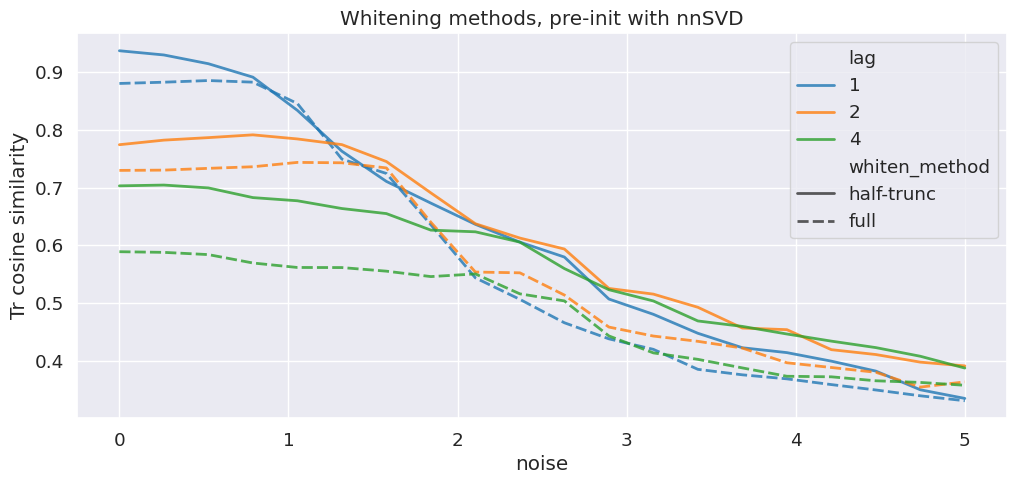

In [27]:
fig = plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_complex[df_complex["pre_init_method"] == "nnsvd"],
    x="noise",
    y="cs_trace",
    hue="lag",
    style="whiten_method",
    palette="tab10",
    linewidth=2,
    alpha=0.8,
)
plt.ylabel("Tr cosine similarity")
plt.title("Whitening methods, pre-init with nnSVD")

Text(0.5, 1.0, 'Whitening methods, pre-init with white-noise')

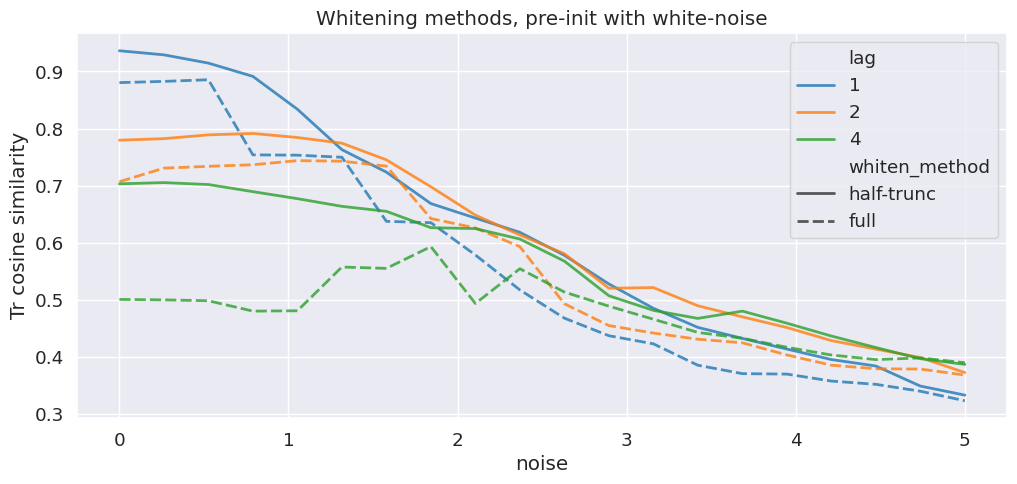

In [28]:
fig = plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_complex[df_complex["pre_init_method"] == "white-noise"],
    x="noise",
    y="cs_trace",
    hue="lag",
    style="whiten_method",
    palette="tab10",
    linewidth=2,
    alpha=0.8,
)
plt.ylabel("Tr cosine similarity")
plt.title("Whitening methods, pre-init with white-noise")

Text(0.5, 1.0, 'Half-trunc whitened: init with nnSVD vs white noise')

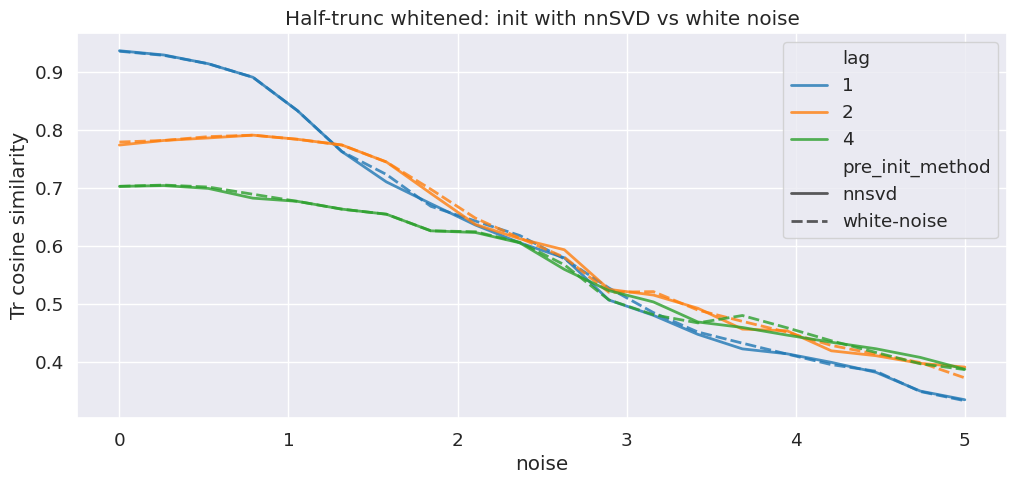

In [33]:
fig = plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_complex[df_complex["whiten_method"] == "half-trunc"],
    x="noise",
    y="cs_trace",
    hue="lag",
    style="pre_init_method",
    palette="tab10",
    linewidth=2,
    alpha=0.8,
)
plt.ylabel("Tr cosine similarity")
plt.title("Half-trunc whitened: init with nnSVD vs white noise")

Text(0.5, 1.0, 'Full whitened: init with nnSVD vs white noise')

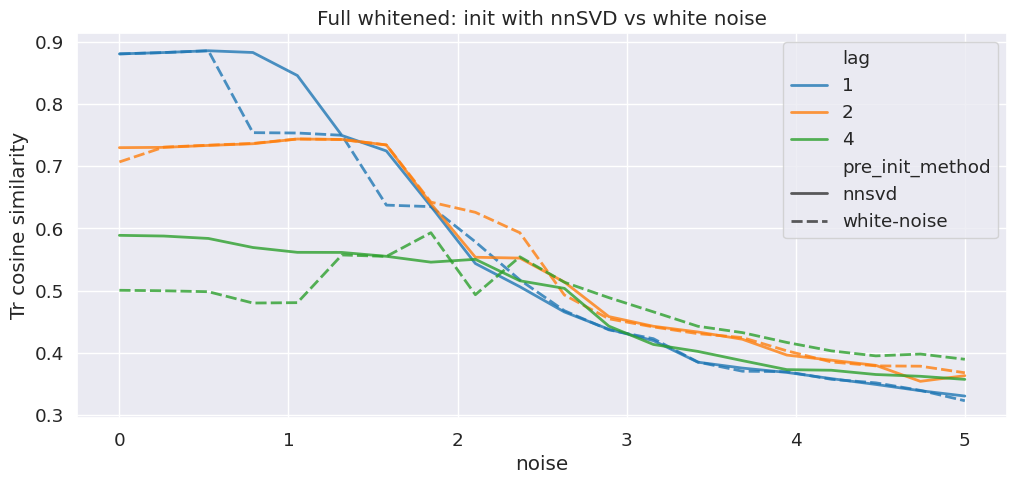

In [32]:
fig = plt.figure(figsize=(12, 5))

sns.lineplot(
    data=df_complex[df_complex["whiten_method"] == "full"],
    x="noise",
    y="cs_trace",
    hue="lag",
    style="pre_init_method",
    palette="tab10",
    linewidth=2,
    alpha=0.8,
)
plt.ylabel("Tr cosine similarity")
plt.title("Full whitened: init with nnSVD vs white noise")